Instalaciones previas

In [1]:
%pip install scikit-learn seaborn

Note: you may need to restart the kernel to use updated packages.


Paquetes necesarios

In [2]:
import cv2  
import numpy as np
import matplotlib.pyplot as plt
import csv

TAREA: Los ejemplos ilustrativos anteriores permiten saber el número de monedas presentes en la imagen ideal proporcionada. ¿Cómo determinar la cantidad de dinero presente en ella? A partir únicamente de las dimensiones, una sugerencia impicaríaj en primer término identificar de forma interactiva (por ejemplo haciendo clic en la imagen) una moneda de un valor fijo en la imagen (por ejemplo de 1€) para permitir establecer una relación entre píxeles y mo¡ilímetros. Tras obtener esa información y las dimensiones en milímetros de las distintas monedas, es factible calcular la cantidad de dinero en la imagen ideal.

Una vez resuelto el reto con la imagen ideal proporcionada, diseña un demostrador en vivo que a partir de la entrada de vídeo de la cámara, determine el dinero presente en la escena. Si bien 
no hay restricciones sobre utilizar medidas geométricas o de color, o cualquier clasificador, no deben hacer uso de modelos de aprendizaje profundo. ¿Funciona correctamente? ¿Se observan problemas?
Posibles extras serían la presencia de objetos que no son monedas y/o haya solape entre las monedas.

IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo

Nota: Para establecer la correspondencia entre píxeles y milímetros, comentar que la moneda de un euro tiene un diámetro de 23.25 mm. la de 50 céntimos de 24.35, la de 20 céntimos de 22.25, etc. 



DATOS Y FUNCIONES COMUNES


In [3]:
# Diámetro oficial (mm) y valor (€) de cada moneda
monedas_euro = {
    '1c':  (16.25, 0.01),
    '2c':  (18.75, 0.02),
    '10c': (19.75, 0.10),
    '5c':  (21.25, 0.05),
    '20c': (22.25, 0.20),
    '1€':  (23.25, 1.00),
    '50c': (24.25, 0.50),
    '2€':  (25.75, 2.00),
}
nombres = list(monedas_euro.keys())
diam_oficiales = np.array([monedas_euro[n][0] for n in nombres])
DIAM_REF_MM = monedas_euro['1€'][0]   # la moneda de referencia es siempre la de 1 €


def mostrar(imagen_bgr, titulo=None):
    """Muestra una imagen BGR con matplotlib (convierte a RGB)."""
    plt.imshow(cv2.cvtColor(imagen_bgr, cv2.COLOR_BGR2RGB))
    if titulo:
        plt.title(titulo)
    plt.axis('off')
    plt.show()


def pedir_clic(imagen, titulo='Haz clic en la moneda de 1 euro (ESC para salir)'):
    """Abre una ventana y devuelve el (x, y) del primer clic, o None si se pulsa ESC."""
    punto = []

    def on_click(event, x, y, flags, param):
        if event == cv2.EVENT_LBUTTONDOWN:
            punto.append((x, y))

    cv2.namedWindow(titulo)
    cv2.setMouseCallback(titulo, on_click)
    while not punto:
        cv2.imshow(titulo, imagen)
        if cv2.waitKey(20) == 27:   # ESC
            break
    cv2.destroyAllWindows()
    return punto[0] if punto else None


def clasificar(diametros_px, mm_por_px):
    """A partir de diámetros en píxeles devuelve (nombres, diámetros en mm, errores en mm).
    Es lo único que comparten las dos soluciones: lo que cambia es cómo se obtiene el diámetro."""
    d_mm = np.asarray(diametros_px, dtype=float) * mm_por_px
    idx = [int(np.argmin(np.abs(diam_oficiales - d))) for d in d_mm]
    etiquetas = [nombres[k] for k in idx]
    errores = [abs(diam_oficiales[k] - d) for k, d in zip(idx, d_mm)]
    return etiquetas, d_mm, errores


def total_euros(etiquetas):
    return sum(monedas_euro[e][1] for e in etiquetas)

PASO 1: DETECTAR Y NUMERAR LAS MONEDAS

(938, 473, 3)


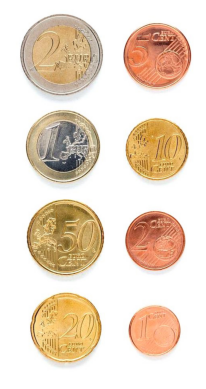

In [6]:
img = cv2.imread('../img/Monedas.jpg')
print(img.shape)
# OpenCV lee en BGR; `mostrar` convierte a RGB para visualizar
mostrar(img)

Moneda 0: centro=(130,114)  radio=104 px  diámetro=208 px
Moneda 1: centro=(140,580)  radio=91 px  diámetro=182 px
Moneda 2: centro=(142,806)  radio=90 px  diámetro=180 px
Moneda 3: centro=(128,346)  radio=87 px  diámetro=174 px
Moneda 4: centro=(374,118)  radio=81 px  diámetro=162 px
Moneda 5: centro=(370,354)  radio=77 px  diámetro=154 px
Moneda 6: centro=(370,586)  radio=75 px  diámetro=150 px
Moneda 7: centro=(366,816)  radio=66 px  diámetro=132 px


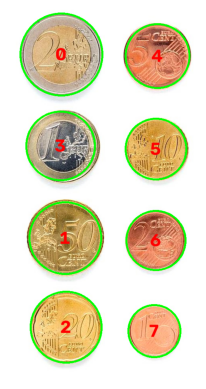

In [7]:
gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
# Suaviza la imagen (elimina altas frecuencias)
pimg = cv2.medianBlur(gris, 7)

circ = cv2.HoughCircles(
    pimg,
    cv2.HOUGH_GRADIENT,
    1,
    100,          # distancia mínima entre círculos
    param1=100,   # valor del gradiente
    param2=50,    # umbral del acumulador
    minRadius=50,
    maxRadius=150,
)

if circ is None:
    raise ValueError("No se encontraron círculos")

circ = np.round(circ[0]).astype(int)

vis = img.copy()
for i, (x, y, r) in enumerate(circ):
    cv2.circle(vis, (x, y), r, (0, 255, 0), 3)
    cv2.putText(vis, str(i), (x - 15, y + 15),
                cv2.FONT_HERSHEY_SIMPLEX, 1.5, (0, 0, 255), 3)
    print(f"Moneda {i}: centro=({x},{y})  radio={r} px  diámetro={2*r} px")

mostrar(vis)

PASO 2: ELEGIR LA MONEDA DE REFERENCIA CON UN CLIC

In [10]:
punto = pedir_clic(vis)
if punto is None:
    raise ValueError("No se hizo clic")

cx, cy = punto
dist = np.hypot(circ[:, 0] - cx, circ[:, 1] - cy)
idx_ref = int(np.argmin(dist))

if dist[idx_ref] > circ[idx_ref, 2]:
    raise ValueError("El clic no cae dentro de ninguna moneda")

d_ref_px = 2 * circ[idx_ref, 2]                 # diámetro de la referencia en píxeles
mm_por_px = DIAM_REF_MM / d_ref_px
print(f"Referencia: moneda {idx_ref}, diámetro {d_ref_px} px")
print(f"Escala: {mm_por_px:.4f} mm/píxel")

Referencia: moneda 3, diámetro 174 px
Escala: 0.1336 mm/píxel


PASO 3: CÁLCULO DEL DINERO (V1, NO FUNCIONA BIEN)


Moneda 0: 27.79 mm -> 2€  (error 2.04 mm)
Moneda 1: 24.32 mm -> 50c  (error 0.07 mm)
Moneda 2: 24.05 mm -> 50c  (error 0.20 mm)
Moneda 3: 23.25 mm -> 1€  (error 0.00 mm)
Moneda 4: 21.65 mm -> 5c  (error 0.40 mm)
Moneda 5: 20.58 mm -> 5c  (error 0.67 mm)
Moneda 6: 20.04 mm -> 10c  (error 0.29 mm)
Moneda 7: 17.64 mm -> 2c  (error 1.11 mm)

TOTAL: 4.22 €


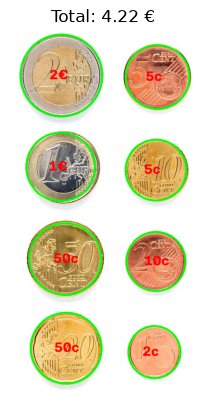

In [11]:
diametros_px = 2 * circ[:, 2]                   # <-- lo único propio de Hough
etiquetas, d_mm, errores = clasificar(diametros_px, mm_por_px)

res = img.copy()
for i, ((x, y, r), nombre) in enumerate(zip(circ, etiquetas)):
    print(f"Moneda {i}: {d_mm[i]:.2f} mm -> {nombre}  (error {errores[i]:.2f} mm)")
    cv2.circle(res, (x, y), r, (0, 255, 0), 3)
    cv2.putText(res, nombre, (x - 30, y + 10),
                cv2.FONT_HERSHEY_SIMPLEX, 1.2, (0, 0, 255), 3)

total = total_euros(etiquetas)
print(f"\nTOTAL: {total:.2f} €")
mostrar(res, f"Total: {total:.2f} €")

SOLUCION POSIBLE: MEDIR CON EL CONTORNO NO CON HOUGH

área de un círculo = π · (d/2)²   →   d = 2 · √(área / π)

PASO 1: SACAMOS LOS CONTORNOS CON LA TÉCNICA NUEVA

In [12]:
gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
gris = cv2.GaussianBlur(gris, (5, 5), 0)

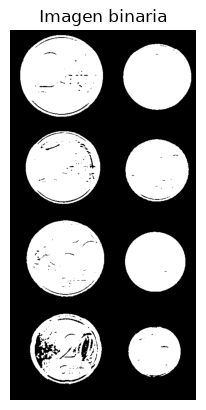

Monedas detectadas: 8


In [13]:
# Monedas -> blanco, fondo -> negro (Otsu elige el umbral solo)
_, binaria = cv2.threshold(gris, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

# Contornos externos, descartando manchas pequeñas
contornos, _ = cv2.findContours(binaria, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
contornos = [c for c in contornos if cv2.contourArea(c) > 1000]

plt.imshow(binaria, cmap='gray'); plt.title('Imagen binaria'); plt.axis('off'); plt.show()
print(f"Monedas detectadas: {len(contornos)}")

PASO 2: MEDIMOS Y ENUMERAMOS LAS MONEDAS

In [14]:
datos = []   # (cx, cy, d_px, contorno)
for c in contornos:
    area = cv2.contourArea(c)
    d_px = 2 * np.sqrt(area / np.pi)            
    M = cv2.moments(c)
    cx, cy = int(M['m10'] / M['m00']), int(M['m01'] / M['m00'])
    datos.append((cx, cy, d_px, c))

Moneda 0: diámetro = 128.5 px
Moneda 1: diámetro = 178.6 px
Moneda 2: diámetro = 151.8 px
Moneda 3: diámetro = 194.1 px
Moneda 4: diámetro = 158.1 px
Moneda 5: diámetro = 185.7 px
Moneda 6: diámetro = 169.0 px
Moneda 7: diámetro = 208.0 px


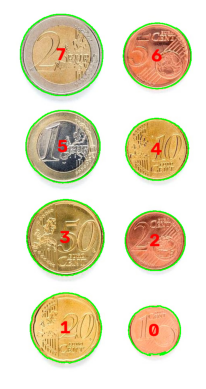

In [15]:
vis = img.copy()
for i, (cx, cy, d_px, c) in enumerate(datos):
    cv2.drawContours(vis, [c], -1, (0, 255, 0), 2)
    cv2.putText(vis, str(i), (cx - 15, cy + 15),
                cv2.FONT_HERSHEY_SIMPLEX, 1.5, (0, 0, 255), 3)
    print(f"Moneda {i}: diámetro = {d_px:.1f} px")

mostrar(vis)

PASO 3: ELEGIR LA MONEDA CON UN CLICK

In [16]:
punto = pedir_clic(vis, 'Clic en la moneda de 1 euro (ESC para salir)')
if punto is None:
    raise ValueError("No se hizo clic")

# ¿Qué contorno contiene el clic?
idx_ref = None
for i, (cx, cy, d_px, c) in enumerate(datos):
    if cv2.pointPolygonTest(c, punto, False) >= 0:
        idx_ref = i
        break

if idx_ref is None:
    raise ValueError("El clic no cae dentro de ninguna moneda")

# La base sigue siendo la moneda de 1 €
mm_por_px = DIAM_REF_MM / datos[idx_ref][2]
print(f"Referencia: moneda {idx_ref}  escala = {mm_por_px:.4f} mm/px")

Referencia: moneda 5  escala = 0.1252 mm/px


PASO 4: CÁLCULO DEL DINERO (FUNCIONA BIEN)

Moneda 0: 16.08 mm -> 1c (error 0.17 mm)
Moneda 1: 22.36 mm -> 20c (error 0.11 mm)
Moneda 2: 19.00 mm -> 2c (error 0.25 mm)
Moneda 3: 24.30 mm -> 50c (error 0.05 mm)
Moneda 4: 19.79 mm -> 10c (error 0.04 mm)
Moneda 5: 23.25 mm -> 1€ (error 0.00 mm)
Moneda 6: 21.16 mm -> 5c (error 0.09 mm)
Moneda 7: 26.04 mm -> 2€ (error 0.29 mm)

TOTAL: 3.88 €


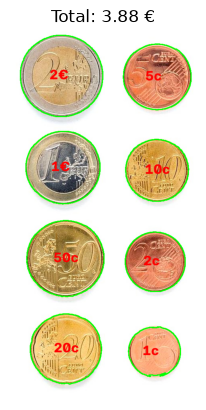

In [17]:
diametros_px = [d[2] for d in datos]            # <-- único cambio respecto a la versión con Hough
etiquetas, d_mm, errores = clasificar(diametros_px, mm_por_px)

res = img.copy()
for i, ((cx, cy, d_px, c), nombre) in enumerate(zip(datos, etiquetas)):
    print(f"Moneda {i}: {d_mm[i]:.2f} mm -> {nombre} (error {errores[i]:.2f} mm)")
    cv2.drawContours(res, [c], -1, (0, 255, 0), 2)
    cv2.putText(res, nombre, (cx - 30, cy + 10),
                cv2.FONT_HERSHEY_SIMPLEX, 1.2, (0, 0, 255), 3)

total = total_euros(etiquetas)
print(f"\nTOTAL: {total:.2f} €")
mostrar(res, f"Total: {total:.2f} €")

AHORA CON AL WEBCAM

PARÁMETROS Y FUNCIONES

In [18]:
# --- Parámetros ajustables (solo Parte 3) ---
INDICE_CAMARA = 1     # si no abre, prueba con 0
AREA_MIN = 1500       # descarta ruido pequeño (px²)
CIRC_MIN = 0.80       # por debajo, no es redonda: objeto raro o monedas solapadas
TOL_MM   = 0.7        # si el diámetro se aleja más de esto de todas las monedas, no es moneda

kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))


def detectar_candidatas(frame):
    """Segmenta el fotograma. Devuelve (candidatas, mascara);
    cada candidata es (cx, cy, d_px, circularidad, contorno)."""
    gris = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    gris = cv2.GaussianBlur(gris, (5, 5), 0)
    # monedas oscuras -> blanco, fondo claro -> negro
    _, mascara = cv2.threshold(gris, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    mascara = cv2.morphologyEx(mascara, cv2.MORPH_CLOSE, kernel)   # rellena reflejos

    contornos, _ = cv2.findContours(mascara, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    candidatas = []
    for c in contornos:
        area = cv2.contourArea(c)
        if area < AREA_MIN:
            continue
        per = cv2.arcLength(c, True)
        circularidad = 4 * np.pi * area / per**2
        d_px = 2 * np.sqrt(area / np.pi)                 # mismo diámetro equivalente que en la imagen estática
        M = cv2.moments(c)
        cx, cy = int(M['m10'] / M['m00']), int(M['m01'] / M['m00'])
        candidatas.append((cx, cy, d_px, circularidad, c))
    return candidatas, mascara


def calibrar_con_clic(candidatas, punto):
    """Devuelve mm/px si el clic cae dentro de una candidata (la moneda de 1 €); si no, None."""
    for cx, cy, d_px, circularidad, c in candidatas:
        if cv2.pointPolygonTest(c, punto, False) >= 0:
            return DIAM_REF_MM / d_px
    return None

BUCLE PRINCIPAL

In [19]:
clic = []
def on_click(event, x, y, flags, param):
    if event == cv2.EVENT_LBUTTONDOWN:
        clic.append((x, y))

mm_por_px = None   # se define al calibrar

vid = cv2.VideoCapture(INDICE_CAMARA)

cv2.namedWindow('Camara')
cv2.setMouseCallback('Camara', on_click)

while True:
    ret, frame = vid.read()
    if not ret:
        break

    candidatas, mascara = detectar_candidatas(frame)

    # Calibración: el último clic fija la escala con la moneda de 1 €
    if clic:
        nueva = calibrar_con_clic(candidatas, clic[-1])
        clic.clear()
        if nueva is not None:
            mm_por_px = nueva
            print(f"Escala: {mm_por_px:.4f} mm/px")

    # Clasificar y sumar
    etiquetas_validas = []
    for cx, cy, d_px, circularidad, c in candidatas:
        if circularidad < CIRC_MIN:
            # No redondo: objeto que no es moneda o monedas pegadas
            cv2.drawContours(frame, [c], -1, (160, 160, 160), 2)
            cv2.putText(frame, "?", (cx - 10, cy + 10),
                        cv2.FONT_HERSHEY_SIMPLEX, 1, (160, 160, 160), 2)
            continue

        if mm_por_px is None:
            cv2.drawContours(frame, [c], -1, (0, 255, 0), 2)
            continue

        (nombre,), _, (error,) = clasificar([d_px], mm_por_px)   # misma función que en la imagen estática

        if error > TOL_MM:
            # Redonda pero no encaja con ninguna moneda
            cv2.drawContours(frame, [c], -1, (0, 0, 255), 2)
            cv2.putText(frame, "no moneda", (cx - 50, cy + 10),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 255), 2)
        else:
            etiquetas_validas.append(nombre)
            cv2.drawContours(frame, [c], -1, (0, 255, 0), 2)
            cv2.putText(frame, nombre.replace('€', 'E'), (cx - 25, cy + 10),   # putText no dibuja €
                        cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 0, 255), 2)

    # Información en pantalla
    if mm_por_px is None:
        texto = "Haz clic en la moneda de 1 euro para calibrar"
    else:
        texto = f"TOTAL: {total_euros(etiquetas_validas):.2f} EUR   (R = recalibrar)"
    cv2.putText(frame, texto, (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 0, 0), 2)

    cv2.imshow('Camara', frame)
    cv2.imshow('Mascara', mascara)

    tecla = cv2.waitKey(20)
    if tecla == 27:                       # ESC: salir
        break
    if tecla in (ord('r'), ord('R')):     # R: recalibrar
        mm_por_px = None

vid.release()
cv2.destroyAllWindows()